In [2]:
import rasterio
import networkx as nx
import numpy as np
import pandas as pd
import geopandas as gpd

In [3]:
import pickle

In [4]:
from rasterio.features import geometry_mask
from scipy.spatial import cKDTree
from shapely.geometry import Point
from shapely.ops import nearest_points

In [5]:
from matplotlib import pyplot as plt
from matplotlib.colors import Normalize

In [6]:
import xarray as xr
from xarray_selafin.xarray_backend import SelafinBackendEntrypoint

In [7]:
import random # undersample trees

In [8]:
import psutil
print(f"RAM usage: {psutil.virtual_memory().percent}%")

RAM usage: 8.3%


In [45]:
# set raster paths
CELL_SIZE = 5.0 # DEM resolution
SLOPE_MEAN = 25.5 # degrees, from input raster stats
SLOPE_STD  = 7.59 # degrees, from input raster stats
MIN_ELEV   = 800 # m, from input raster stats, for plotting later

# tune this from literature 
BREACH_ANGLE = SLOPE_MEAN - 2*SLOPE_STD # tail, 3rd STDV
assert(BREACH_ANGLE > 1e-5) # must be positive


dem_path = "../data/elevs/nwdomain2000_elev5m.tif"
slope_path = "../data/elevs/nwdomain2000_slope5m.tif"
aspect_path = "../data/elevs/nwdomain2000_aspect5m.tif"

In [10]:
# set basin mask
basin_path = '../data/outlines/wbasin_utm.gpkg'

In [11]:
def make_basin_mask(dem_file, basin_file):
    ''' 
    dem_file: the DEM underlying graph construction
    basin_file: polygon to mask the basin cells
            -- files must overlap! --
    '''
    # retrieve coordinate system
    with rasterio.open(dem_file) as src:
        dem_crs = src.crs

    # retrieve coastline and reproject
    basin_line = gpd.read_file(basin_file)
    basin_line = basin_line.to_crs(dem_crs)

    # retrieve extent for later
    bounds = src.bounds
    extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

    # Create a mask for ocean areas
    with rasterio.open(dem_file) as src:
        dem_data = src.read(1)
        transform = src.transform
    
        # rasterize the coast polygon
        # mask=True means ocean True, land False
        basin_mask = geometry_mask(
                basin_line.geometry,
                out_shape=dem_data.shape,
                transform=transform, # from src above
                invert=True # true where polygon exists (ocean)
        )
    return basin_mask, transform, extent

# original, no breach
def diGraph_from_dem(dem_path,slope_path,aspect_path,
                      basin_mask,basin_level=-99.0,cell_size=CELL_SIZE):
     
    """
    Builds a directed graph from a LiDAR-derived DEM (TIFF)
    
    Args: 
        dem_path, slope_path, aspect_path (str): paths to TIFF files
        basin_mask: basin mask built from make_basin_mask
        basin_leval: distinguish basin from slope by extreme low elev value
        cell_size (float): size of DEM cell
        
        implicit: connectivity (int): assumes 8 - cardinals plus diagonals
    
    Returns:
        graph (nx.DiGraph): a directed graph such that each node
            corresponds to a dem cell from the raster with:
            - node attributes:
                - elev (float): the elevation of the cell
                - slope (float): topographic slope in the cell
                - aspect_sin (float): sin of the topographic aspect
                - aspect_cos (float): cos of the topographic aspect
                - dist_from_basin_path: length of shortest path to basin (in units of elev raster)
                - isPit (boolean): marking cell as pit (no outlet)
                - isSource (boolean): marking as source (no inlet)
                - node_idx (int, int): indices of the node on the dem tile
            - edge attributes:
                - weight (float): absolute value of slope between two nodes
    
    Terms:
        pit - node with no neighbors lower than itself and at least one higher
        source - node with no neighbors lower than itself and at least one lower
    
    """

    with rasterio.open(dem_path) as src:
        dem_data = src.read(1)
        height, width = dem_data.shape

    # set basin cells to very low (and uniform) elevation
    # will enforce pit creation precisely at boundary
    # and no source/sink/node creation in basin
    dem_mod = dem_data.copy() # keep original for plotting
    dem_mod[basin_mask] = basin_level 

    with rasterio.open(aspect_path) as srca:
        aspect_data = srca.read(1)
        # verify
        aheight, awidth = aspect_data.shape
        if aheight != height or awidth != width:
            print("aspect-elev dimension mismatch")
            return
        else:
            asp = np.deg2rad(aspect_data.copy())
            asp_sin = np.sin(asp).astype(np.float32)
            asp_cos = np.cos(asp).astype(np.float32)

    with rasterio.open(slope_path) as srcs:
        slope_data = srcs.read(1)
        # verify
        sheight, swidth = slope_data.shape
        if sheight != height or swidth != width:
            print("slope-elev dimension mismatch")
    
    num_nodes = height*width
    graph = nx.DiGraph()
    

    # track source, basinPit, and slopeSink nodes
    sourceList = []
    basinPitList = []
    slopeSinkList = []
    
    # assuming cardinal and diagonal neighbors
    neighbors = [(-1,0), (1,0), (0,1), (0,-1),
                 (-1,-1), (-1,1), (1,-1), (1,1)]
    
    
    
    for r in range(height):
        if r % 100 == 0:  # Check every 100 rows
                ram = psutil.virtual_memory().percent
                print(f"Row {r}/{height}, RAM: {ram:.1f}%")
            
        for c in range(width):
            current_node_idx = r * width + c # iterates through num_nodes
            # Add node with attributes
            graph.add_node(current_node_idx, 
                           dem_idx=[r,c], 
                           elev=dem_mod[r,c],
                           slope=slope_data[r,c],
                           aspect_sin=asp_sin[r,c],
                           aspect_cos=asp_cos[r,c],
                           dist_from_pit_path = -99.0, # dummy value to ensure float
                           is_slopeSink=False,
                           is_basinPit=False,
                           is_source=False)

            next_node = current_node_idx
            minSlope = 0
            maxSlope = 0
            # note: minSlope can never > 0 and maxSlope never < 0
            # from construction below
            
            for dr, dc in neighbors:
                nr, nc = r + dr, c + dc
    
                if 0 <= nr < height and 0 <= nc < width: # check nr, nc in bounds
                    neighbor_node_idx = nr*width + nc # index in lil_matrix
                    
                    # neigbor - center: negative implies downslope from center
                    slope = dem_mod[nr,nc] - dem_mod[r,c]
                    slope = slope / (np.linalg.norm([dr,dc])*cell_size) # normalize
                    
                    if slope < minSlope:
                        minSlope = slope
                        next_node = neighbor_node_idx
                    elif slope > maxSlope:
                        maxSlope = slope
                        
            
            #after looping through neighbors of r,c
            if minSlope < 0:
                wgt = abs(minSlope)
                graph.add_edge(current_node_idx, next_node, weight=wgt)
                if maxSlope == 0: # outflow + no inflow = source # orig "=="
                    graph.nodes[current_node_idx]["is_source"] = True
                    sourceList.append(current_node_idx)
            elif minSlope == 0 and maxSlope > 0 and dem_mod[r,c] == basin_level: 
                # basinPit: no outlets, has inflow, has reached basin:
                    graph.nodes[current_node_idx]["is_basinPit"] = True
                    basinPitList.append(current_node_idx)
            elif minSlope == 0 and maxSlope > 0 and dem_mod[r,c] != basin_level:
                # slopeSink: no outlets, has inflow, not at basin:
                    graph.nodes[current_node_idx]["is_slopeSink"] = True
                    slopeSinkList.append(current_node_idx)


    print("source count: " + str(len(sourceList)))
    print("basin pit count: " + str(len(basinPitList)))
    print("slope sink count: " + str(len(slopeSinkList)))
    
    return graph, sourceList, basinPitList, slopeSinkList, dem_data, dem_mod

In [31]:
# breach by breach_angle
def diGraph_from_dem(dem_path,slope_path,aspect_path,
                      basin_mask,basin_level=-99.0,
                     cell_size=CELL_SIZE,breach_angle=BREACH_ANGLE):
     
    """
    Builds a directed graph from a LiDAR-derived DEM (TIFF)
    
    Args: 
        dem_path, slope_path, aspect_path (str): paths to TIFF files
        basin_mask: basin mask built from make_basin_mask
        basin_leval: distinguish basin from slope by extreme low elev value
        cell_size (float): size of DEM cell
        
        implicit: connectivity (int): assumes 8 - cardinals plus diagonals
    
    Returns:
        graph (nx.DiGraph): a directed graph such that each node
            corresponds to a dem cell from the raster with:
            - node attributes:
                - elev (float): the elevation of the cell
                - slope (float): topographic slope in the cell
                - aspect_sin (float): sin of the topographic aspect
                - aspect_cos (float): cos of the topographic aspect
                - dist_from_basin_path: length of shortest path to basin (in units of elev raster)
                - isPit (boolean): marking cell as pit (no outlet)
                - isSource (boolean): marking as source (no inlet)
                - node_idx (int, int): indices of the node on the dem tile
            - edge attributes:
                - weight (float): absolute value of slope between two nodes
    
    Terms:
        pit - node with no neighbors lower than itself and at least one higher
        source - node with no neighbors lower than itself and at least one lower
    
    """

    with rasterio.open(dem_path) as src:
        dem_data = src.read(1)
        height, width = dem_data.shape

    # set basin cells to very low (and uniform) elevation
    # will enforce pit creation precisely at boundary
    # and no source/sink/node creation in basin
    dem_mod = dem_data.copy() # keep original for plotting
    dem_mod[basin_mask] = basin_level 

    with rasterio.open(aspect_path) as srca:
        aspect_data = srca.read(1)
        # verify
        aheight, awidth = aspect_data.shape
        if aheight != height or awidth != width:
            print("aspect-elev dimension mismatch")
            return
        else:
            asp = np.deg2rad(aspect_data.copy())
            asp_sin = np.sin(asp).astype(np.float32)
            asp_cos = np.cos(asp).astype(np.float32)

    with rasterio.open(slope_path) as srcs:
        slope_data = srcs.read(1)
        # verify
        sheight, swidth = slope_data.shape
        if sheight != height or swidth != width:
            print("slope-elev dimension mismatch")
    
    num_nodes = height*width
    graph = nx.DiGraph()
    

    # track source, basinPit, and slopeSink nodes
    sourceList = []
    basinPitList = []
    localSinkList = [] # slope sinks allowed to breach
    absSinkList = []   # slope sinks not able to breach
    
    # assuming cardinal and diagonal neighbors
    neighbors = [(-1,0), (1,0), (0,1), (0,-1),
                 (-1,-1), (-1,1), (1,-1), (1,1)]
    
    
    
    for r in range(height):
        if r % 100 == 0:  # Check every 100 rows
                ram = psutil.virtual_memory().percent
                print(f"Row {r}/{height}, RAM: {ram:.1f}%")
            
        for c in range(width):
            current_node_idx = r * width + c # iterates through num_nodes
            # Add node with attributes
            graph.add_node(current_node_idx, 
                           dem_idx=[r,c], 
                           elev=dem_mod[r,c],
                           slope=slope_data[r,c],
                           aspect_sin=asp_sin[r,c],
                           aspect_cos=asp_cos[r,c],
                           dist_from_pit_path = -99.0, # dummy value to ensure float
                           is_localSink=False,
                           is_absSink=False,
                           is_basinPit=False,
                           is_source=False)

            next_node = current_node_idx
            minSlope = breach_angle # any negative number will replace this
            maxSlope = 0
            
            for dr, dc in neighbors:
                nr, nc = r + dr, c + dc
    
                if 0 <= nr < height and 0 <= nc < width: # check nr, nc in bounds
                    neighbor_node_idx = nr*width + nc # index in lil_matrix
                    
                    # neigbor - center: negative implies downslope from center
                    slope = dem_mod[nr,nc] - dem_mod[r,c]
                    slope = slope / (np.linalg.norm([dr,dc])*cell_size) # normalize
                    
                    if slope < minSlope:
                        minSlope = slope
                        next_node = neighbor_node_idx
                    if slope > maxSlope:
                        maxSlope = slope
                        
            
            #after looping through neighbors of r,c
            # breaching condition is minSlope < MEAN_SLOPE / 2.0
            if minSlope < breach_angle - 1e-5:
                wgt = abs(minSlope)
                graph.add_edge(current_node_idx, next_node, weight=wgt)
                if minSlope < 0 and maxSlope == 0: # outflow + no inflow = source # orig "=="
                    graph.nodes[current_node_idx]["is_source"] = True
                    sourceList.append(current_node_idx)
                elif minSlope >= 0: # no true outflow
                    if maxSlope > 0 and dem_mod[r,c] == basin_level: 
                        # basinPit: no outlets, has inflow, has reached basin:
                        graph.nodes[current_node_idx]["is_basinPit"] = True
                        basinPitList.append(current_node_idx)
                    else: # outflow by breach only
                        graph.nodes[current_node_idx]["is_localSink"] = True
                        localSinkList.append(current_node_idx)
            elif minSlope >= breach_angle and dem_mod[r,c] != basin_level:
                # absolute slope sink: no (breached) outlets, has inflow, not at basin:
                # note: maxSlope necessarily > 0 if minSlope 
                    graph.nodes[current_node_idx]["is_absSink"] = True
                    absSinkList.append(current_node_idx)


    print("source count: " + str(len(sourceList)))
    print("basin pit count: " + str(len(basinPitList)))
    print("absolute sink count: " + str(len(absSinkList)))
    print("breached sink count: " + str(len(localSinkList)))
    
    return graph, sourceList, basinPitList, localSinkList, absSinkList, dem_data, dem_mod

In [14]:
# retrive the ocean mask to use in graph construction
# transform and extent for later use
basin_mask, transform, extent = make_basin_mask(dem_path, basin_path)

In [32]:
# retrieve the directed dem graph and the list of coastal pit nodes
canWolfGraph, sourceList, basinPitList, localSinkList, absSinkList, dem_data, dem_mod = diGraph_from_dem(dem_path, slope_path, aspect_path, basin_mask)

Row 0/1156, RAM: 41.7%
Row 100/1156, RAM: 42.8%
Row 200/1156, RAM: 44.1%
Row 300/1156, RAM: 45.6%
Row 400/1156, RAM: 46.9%
Row 500/1156, RAM: 32.7%
Row 600/1156, RAM: 33.9%
Row 700/1156, RAM: 35.2%
Row 800/1156, RAM: 36.4%
Row 900/1156, RAM: 37.7%
Row 1000/1156, RAM: 39.5%
Row 1100/1156, RAM: 40.8%
source count: 3972
basin pit count: 1573
absolute sink count: 0
breached sink count: 1276640


In [23]:
import sys
print(sys.getsizeof(dem_data))

6667936


In [34]:
# checkpoint 1
# re-retrieve basin_mask etc. after loading
save_graph = {
    'canWolfGraph_std3breach': canWolfGraph,        # full graph with all attributes
    'dem_data': dem_data,                # For plotting
    'dem_mod' : dem_mod,                 # for basin
    'basinPitList' : basinPitList, 
    'sourceList'   : sourceList,
    'localSinkList': localSinkList,
    'absSinkList'  : absSinkList,
    'basin_mask':basin_mask,
    'transform' :transform,
    'extent'    :extent
}

In [35]:
with open('canwellWolfGraph_std3breach.pkl','wb') as f:
    pickle.dump(save_graph,f)
print("saved!")

saved!


In [17]:
# OLD step 1 ## assign stability labels ##
# now? DDEM? Horton's? Hack's?

In [36]:
# 1.5.1 function to trace tree subgraphs from a coastal pit node
def trace_tree_from_pit(graph, pit_node, max_depth=1000):
    """
    Traces all upstream nodes that flow into the given pit.
    
    NOPE!!:::TODO::: incorporate count distance from pit for each node
    
    Args:
        graph: NetworkX DiGraph
        pit_node: Starting node (pit/outlet)
        max_depth: Maximum number of nodes to prevent infinite loops
        
    Returns:
        subgraph: Subgraph containing the tree
    """
    visited = set()
    to_visit = [pit_node]
    
    while to_visit and len(visited) < max_depth:
        current = to_visit.pop(0)
        
        if current in visited:
            continue
            
        visited.add(current)
        
        # Get all nodes that flow INTO current node
        predecessors = list(graph.predecessors(current))
        to_visit.extend(predecessors)
    
    # Create subgraph from visited nodes
    tree_subgraph = graph.subgraph(visited).copy()
    
    # print(f"Tree has {len(visited)} nodes")
    return tree_subgraph

In [37]:
# 1.5.2 keep drainage trees larger than a threshold (50)
basinPit_trees = {}
threshold = 50
for pit_idx in basinPitList:
    tree = trace_tree_from_pit(canWolfGraph, pit_idx)
    if tree.number_of_nodes() > threshold:
        basinPit_trees[pit_idx] = tree
print(f"basinPit trees size > {threshold}: {len(basinPit_trees)}")

basinPit trees size > 50: 1541


In [51]:
### CAUTION!! ###
# ensure save_dict** and SU**_trees and wolfGraphSU** line up # 
# i.e. avoid overwriting the wrong file #
assert False # halts automatic execution of saving cells


AssertionError: 

In [52]:
# step 6 ## SAVE ## (and don't rm -f !!)
# use git rm --cached file.pkl # instead! #

In [47]:
## plot and analyze ##

In [44]:
# distribution of non-channel pit distances from channel
from scipy.ndimage import distance_transform_edt
slope_sink_ids = localSinkList
# distance (in cells = meters) from every cell to the nearest channel cell
dist_to_channel = distance_transform_edt(~basin_mask)

# distance for each non-channel pit node
sink_dists = np.array([dist_to_channel[canWolfGraph.nodes[p]['dem_idx'][0],
                                       canWolfGraph.nodes[p]['dem_idx'][1]]
                       for p in slope_sink_ids])

print(f"breached slope sinks: {len(sink_dists)}")
print(f" distance to basin stats:\n  min {sink_dists.min():.1f} m | median {np.median(sink_dists):.1f} m | max {sink_dists.max():.1f} m")
for D in (50, 100, 150, 200, 300, 400, 600, 800, 1000):
    print(f"  within {D:>3} m of basin: {(sink_dists <= D).sum():>3}")

breached slope sinks: 1276640
 distance to basin stats:
  min 0.0 m | median 161.1 m | max 826.7 m
  within  50 m of basin: 419421
  within 100 m of basin: 517769
  within 150 m of basin: 617367
  within 200 m of basin: 705968
  within 300 m of basin: 883532
  within 400 m of basin: 1017550
  within 600 m of basin: 1215950
  within 800 m of basin: 1275867
  within 1000 m of basin: 1276640


In [48]:
# DEM for plotting background
dem_nan = dem_mod.copy()
dem_nan[dem_nan == -9999] = None # NaN outside polygon
dem_nan[dem_nan == -999] = MIN_ELEV - 100.0  # uniform basin level

In [ ]:
# plot slope-drain trees topographically

basin_pit_ids = list(basinPit_trees.keys())


plt.rcParams.update({'font.size': 16}) # Set the global font size to 16

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(dem_nan, cmap='terrain')


# Plot basin pit trees
for pit in basin_pit_ids:
    tree = basinPit_trees[pit]
    
    # mark each node in tree
    for node in tree.nodes():
        r, c = tree.nodes[node]['dem_idx']
        ax.plot(c, r, 'mo', markersize=1, alpha=0.5, label='slope nodes')
    # mark pit
    pit_r, pit_c = tree.nodes[pit]['dem_idx']
    ax.plot(pit_c, pit_r, 'r^', markersize=2,label='basin pits')



# Add scale bar (1 km = 200 pixels at 5m resolution)
# Scale bar - 1 km at 5m resolution = 200 pixels
scale_pixels = 200
scale_x = 1000
scale_y = 1000
bar_height = 15
# White background for readability
ax.add_patch(plt.Rectangle((scale_x - 10, scale_y - 30), 
             scale_pixels + 20, 60, 
             facecolor='white', alpha=0.8, edgecolor='none'))
# Scale bar
ax.plot([scale_x, scale_x + scale_pixels], [scale_y, scale_y], 
        'k-', linewidth=3)
# End ticks
ax.plot([scale_x, scale_x], [scale_y - bar_height, scale_y + bar_height], 
        'k-', linewidth=2)
ax.plot([scale_x + scale_pixels, scale_x + scale_pixels], 
        [scale_y - bar_height, scale_y + bar_height], 
        'k-', linewidth=2)
# Label
ax.text(scale_x + scale_pixels/2, scale_y - 35, '1 km',
        ha='center', va='bottom', fontsize=11,
        color='black', fontweight='bold')
## end scale bar ##

# title
ax.set_title(f"Canwell NW Slope {len(basin_pit_ids)} drain-graph trees -- 3std breach\n IfSAR 2000, 5m resolution",fontweight='bold')
plt.legend(loc='upper left',fontsize=14)
#plt.savefig("fig_nwdraintrees_breach.png")
plt.show()

# visualize abstract trees
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

# Pick 2 stable, 2 unstable
stable_pits = [p for p in SU_trees.keys() if wolfGraph.nodes[p]['stability'] == 'S'][2:4][::-1] # flip order for asthetic purposes only
unstable_pits = [p for p in SU_trees.keys() if wolfGraph.nodes[p]['stability'] == 'U'][:2]
selected_pits = stable_pits + unstable_pits

for ax, pit_idx in zip(axes, selected_pits):
    tree = SU_trees[pit_idx]
    stability = wolfGraph.nodes[pit_idx]['stability']
    
    # Layout - try hierarchical for flow trees
    pos = nx.spring_layout(tree, k=0.5, iterations=50)
    # OR better for flow: nx.kamada_kawai_layout(tree)
    
    # Color edges by slope (weight)
    edge_weights = [tree.edges[e]['weight'] for e in tree.edges()]
    norm = Normalize(vmin=np.percentile(edge_weights, 10),  # Ignore lowest 10%
                 vmax=np.percentile(edge_weights, 90))  # And highest 10%
    
    # Draw
    nx.draw_networkx_nodes(tree, pos, ax=ax, 
                          node_color='k', 
                          node_size=30, alpha=0.7)
    
    nx.draw_networkx_edges(tree, pos, ax=ax,
                      edge_color=edge_weights,
                      edge_cmap=plt.cm.plasma,  # Try plasma or viridis
                      edge_vmin=norm.vmin,
                      edge_vmax=norm.vmax,
                      width=1.5, alpha=0.8,
                      arrows=True, arrowsize=8)
    
    # Highlight pit node
    # Pit = node with out_degree of 0
    pit_node = [n for n in tree.nodes() if tree.out_degree(n) == 0][0]
    # pit_pos = {pit_node: -pos[pit_node]}
    nx.draw_networkx_nodes(tree, pos, ax=ax, nodelist=[pit_node],
                          node_color='red', node_size=400, 
                          node_shape='v')
    
    # Get features
    max_eros = wolfGraph.nodes[pit_idx]['max_erosive_power']
    tidal = wolfGraph.nodes[pit_idx]['tidal_range']
    inflow = tree.nodes[pit_idx]['total_inflow']
    
    # Title with features
    color = 'green' if stability == 'S' else 'firebrick'
    ax.set_title(f"{stability} Bluff\nTree # {pit_node} (n={tree.number_of_nodes()})\nErosive: {max_eros:.2f} | Tide: {tidal:.1f}m | Inflow: {inflow:.1f}",
                fontsize=18, fontweight='bold', color=color,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
    
    ax.axis('off')

plt.suptitle('Flow Network Structure: Graph Representation\n ', 
            fontsize=24, fontweight='bold')
plt.tight_layout()
#plt.savefig('fig_4trees_abstract.png', dpi=300, bbox_inches='tight')
plt.show()

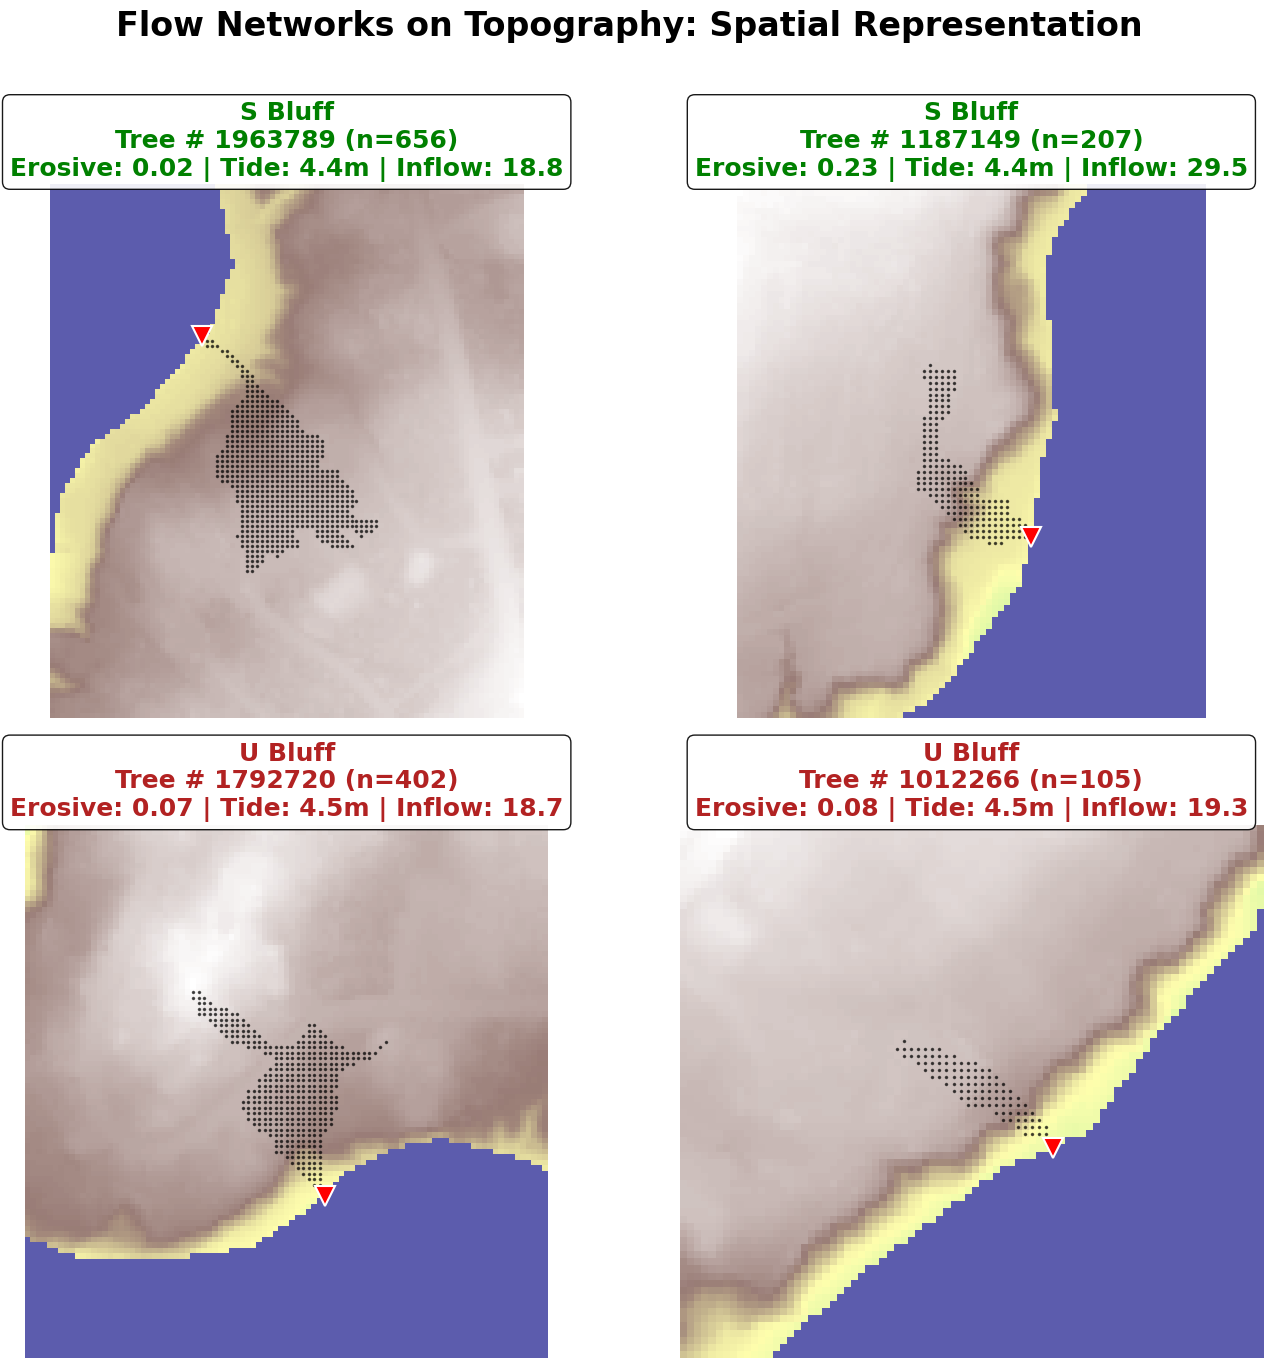

In [66]:
# visualize trees with topographic structure
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
axes = axes.flatten()

# take any four pits
selected_pits = basin_pit_ids[0:4]

for ax, pit_idx in zip(axes, selected_pits):
    tree = basinPit_trees[pit_idx]
    
    # Get bounding box for tree
    tree_nodes = list(tree.nodes())
    rows = [wolfGraph.nodes[n]['dem_idx'][0] for n in tree_nodes]
    cols = [wolfGraph.nodes[n]['dem_idx'][1] for n in tree_nodes]
    
    # Add buffer around tree
    r_min, r_max = max(0, min(rows) - 30), min(dem_data.shape[0], max(rows) + 30)
    c_min, c_max = max(0, min(cols) - 30), min(dem_data.shape[1], max(cols) + 30)
    
    # Crop DEM
    dem_crop = dem_data[r_min:r_max, c_min:c_max]
    
    # Plot hillshade
    ax.imshow(dem_crop, cmap='terrain', alpha=0.8)
    
    # Plot tree nodes (small blue dots)
    for node in tree_nodes:
        r, c = wolfGraph.nodes[node]['dem_idx']
        r_local = r - r_min
        c_local = c - c_min
        ax.plot(c_local, r_local, 'o', color='k', markersize=1.5, alpha=0.6)
    
    # Find and highlight pit node
    pit_node = [n for n in tree.nodes() if tree.out_degree(n) == 0][0]
    pit_r, pit_c = wolfGraph.nodes[pit_node]['dem_idx']
    pit_r_local = pit_r - r_min
    pit_c_local = pit_c - c_min
    ax.plot(pit_c_local, pit_r_local, 'v', color='red', markersize=14, 
            markeredgecolor='white', markeredgewidth=1.5)
    
    # Get features
    # max_eros = wolfGraph.nodes[pit_idx]['max_erosive_power']
    # tidal = wolfGraph.nodes[pit_idx]['tidal_range']
    # inflow = tree.nodes[pit_node]['total_inflow']
    
    # Title with features
    color = 'black' # if stability == 'S' else 'firebrick'
    '''
    ax.set_title(f"{stability} Bluff\nTree # {pit_node} (n={tree.number_of_nodes()})\n" + 
                f"Erosive: {max_eros:.2f} | Tide: {tidal:.1f}m | Inflow: {inflow:.1f}",
                fontsize=18, fontweight='bold', color=color,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
    '''
    
    ax.axis('off')

plt.suptitle('Flow Networks on Topography: Spatial Representation\n ', 
            fontsize=24, fontweight='bold')
plt.tight_layout()
# plt.savefig('fig_4trees_spatial.png', dpi=300, bbox_inches='tight')
plt.show()